# Apache Spark: Beginner to Advanced
**Part of: Building Automated Data Pipelines with Spark, dbt and Airflow**

Everything runs locally (no cluster needed). The notebook is split in three levels:

| Level | You will learn |
|---|---|
| 🟢 Beginner | SparkSession, DataFrames, select/filter/groupBy, reading & writing files |
| 🟡 Intermediate | Joins, window functions, Spark SQL, partitioning, Parquet |
| 🔴 Advanced | Lazy evaluation & `explain()`, shuffles, AQE, broadcast joins, skew & salting, caching, SCD2 merge, streaming, testing |

In [ ]:
%pip install -q pyspark pandas matplotlib

---
# 🟢 Level 1 - Beginner

## 1.1 What is Spark?
Spark is a distributed engine for processing large datasets. You write code on the **driver**; Spark splits the work into **tasks** that run in parallel on **executors**. A **cluster manager** (YARN, Kubernetes, Standalone, or `local[*]` on your laptop) hands out resources.

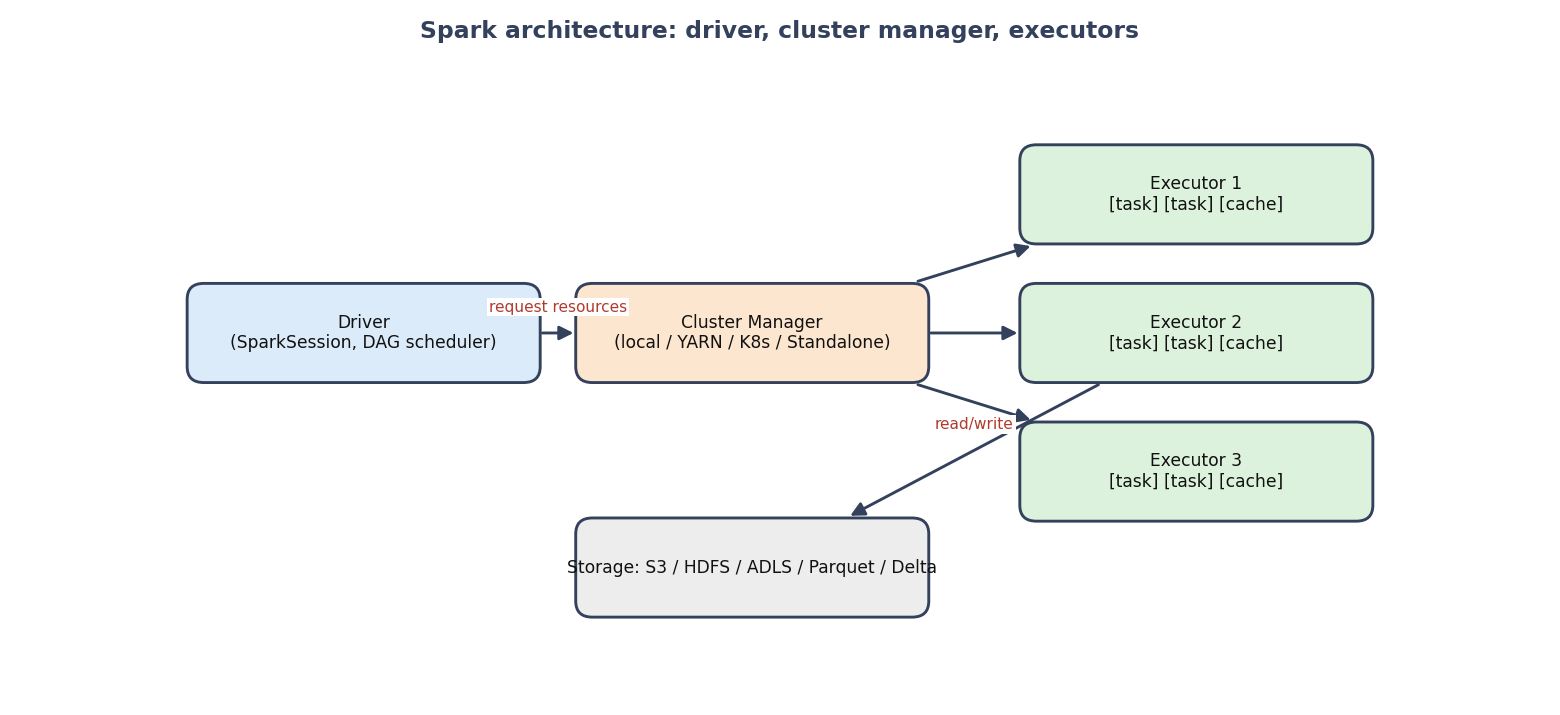

*Driver → Cluster manager → Executors, reading/writing shared storage.*

## 1.2 Start a SparkSession
`SparkSession` is your entry point to everything (DataFrames, SQL, streaming).

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F, types as T

spark = (SparkSession.builder
         .appName("spark-beginner-to-advanced")
         .master("local[*]")                       # use all local cores
         .config("spark.sql.shuffle.partitions", "8")  # small data -> fewer shuffle partitions
         .getOrCreate())
print("Spark version:", spark.version)

## 1.3 Your first DataFrame

In [ ]:
orders_data = [
    (1, "C1", "2026-01-05", "laptop", 2, 950.0),
    (2, "C2", "2026-01-06", "phone",  1, 600.0),
    (3, "C1", "2026-01-09", "phone",  3, 600.0),
    (4, "C3", "2026-02-01", "tablet", 1, 400.0),
    (5, "C2", "2026-02-03", "laptop", 1, 950.0),
    (6, "C4", "2026-02-10", "phone",  2, 600.0),
]
orders = spark.createDataFrame(orders_data, ["order_id", "customer_id", "order_date", "product", "qty", "unit_price"])
orders.show()
orders.printSchema()

## 1.4 Select, filter, add columns
These are **transformations**: they describe what to do, nothing runs until you call an **action** like `show()`, `count()` or `write`.

In [ ]:
df = (orders
      .withColumn("order_date", F.to_date("order_date"))
      .withColumn("revenue", F.col("qty") * F.col("unit_price"))
      .filter(F.col("revenue") > 700)
      .select("order_id", "customer_id", "product", "revenue"))
df.show()

## 1.5 Aggregations

In [ ]:
(orders.withColumn("revenue", F.col("qty") * F.col("unit_price"))
       .groupBy("product")
       .agg(F.sum("revenue").alias("total_revenue"),
            F.count("*").alias("orders"),
            F.round(F.avg("revenue"), 2).alias("avg_order"))
       .orderBy(F.desc("total_revenue"))
       .show())

## 1.6 Reading and writing files

In [ ]:
import os, shutil
os.makedirs("data", exist_ok=True)
shutil.rmtree("data/orders_csv", ignore_errors=True)

orders.coalesce(1).write.mode("overwrite").option("header", True).csv("data/orders_csv")
back = spark.read.option("header", True).option("inferSchema", True).csv("data/orders_csv")
back.printSchema()
back.show(3)

### ✅ Beginner exercises
1. Add a `month` column (`F.month`) and compute revenue per month.
2. Find the customer with the most orders.
3. Write the result as JSON (`.write.json(...)`).

---
# 🟡 Level 2 - Intermediate

## 2.1 Joins

In [ ]:
customers = spark.createDataFrame(
    [("C1", "Asha", "Mauritius"), ("C2", "Ben", "Kenya"), ("C3", "Chen", "China"), ("C5", "Eve", "UK")],
    ["customer_id", "name", "country"])

orders.join(customers, "customer_id", "inner").select("order_id", "name", "country").show()
print("LEFT join keeps all orders (C4 has no customer):")
orders.join(customers, "customer_id", "left").select("order_id", "customer_id", "name").show()
print("ANTI join: orders with no known customer:")
orders.join(customers, "customer_id", "left_anti").show()

## 2.2 Window functions
Rank, running totals and 'previous row' logic without collapsing rows.

In [ ]:
from pyspark.sql import Window

o = orders.withColumn("order_date", F.to_date("order_date")).withColumn("revenue", F.col("qty") * F.col("unit_price"))

w_cust = Window.partitionBy("customer_id").orderBy("order_date")
(o.withColumn("order_no", F.row_number().over(w_cust))
  .withColumn("running_revenue", F.sum("revenue").over(w_cust))
  .withColumn("prev_order_date", F.lag("order_date").over(w_cust))
  .withColumn("days_since_prev", F.datediff("order_date", "prev_order_date"))
  .orderBy("customer_id", "order_date")
  .show())

## 2.3 Spark SQL
DataFrames and SQL are interchangeable: pick whichever reads better.

In [ ]:
o.createOrReplaceTempView("orders")
spark.sql('''
    SELECT product,
           COUNT(*)                        AS orders,
           SUM(revenue)                    AS revenue,
           RANK() OVER (ORDER BY SUM(revenue) DESC) AS rev_rank
    FROM orders
    GROUP BY product
''').show()

## 2.4 Data cleaning toolkit

In [ ]:
dirty = spark.createDataFrame(
    [(1, " Asha ", None), (2, "BEN", "ben@x.com"), (2, "BEN", "ben@x.com"), (3, None, "chen@x.com")],
    ["id", "name", "email"])

clean = (dirty.dropDuplicates()
              .withColumn("name", F.initcap(F.trim("name")))
              .fillna({"name": "Unknown", "email": "n/a"}))
clean.show()

## 2.5 Built-in functions vs UDFs
Built-ins run inside the JVM's optimizer; Python UDFs ship every row to Python. **Prefer built-ins**; if you must, use a *pandas UDF*.

In [ ]:
import pandas as pd
from pyspark.sql.functions import udf, pandas_udf

@udf(T.StringType())
def tier_slow(rev):                       # row-at-a-time: slow
    return "high" if rev >= 1000 else "low"

@pandas_udf(T.StringType())
def tier_vec(rev: pd.Series) -> pd.Series:    # vectorised: much faster
    return rev.apply(lambda r: "high" if r >= 1000 else "low")

fast_builtin = F.when(F.col("revenue") >= 1000, "high").otherwise("low")   # fastest

o.select("order_id", "revenue", tier_slow("revenue").alias("slow"),
         tier_vec("revenue").alias("vec"), fast_builtin.alias("builtin")).show()

## 2.6 Parquet & partitioning
Parquet is columnar and compressed. `partitionBy` lays files out in folders so queries can **skip** data (partition pruning).

In [ ]:
import shutil
shutil.rmtree("data/orders_parquet", ignore_errors=True)
(o.withColumn("month", F.date_format("order_date", "yyyy-MM"))
  .write.mode("overwrite").partitionBy("month").parquet("data/orders_parquet"))

print(sorted(os.listdir("data/orders_parquet")))

jan = spark.read.parquet("data/orders_parquet").filter("month = '2026-01'")
jan.explain()          # look for PartitionFilters in the plan
jan.show()

### ✅ Intermediate exercises
1. Rank products by revenue **within each country** (join + window).
2. Compute a 2-order moving average of revenue per customer (`rowsBetween(-1, 0)`).
3. Save as Parquet partitioned by `country` and confirm pruning with `explain()`.

---
# 🔴 Level 3 - Advanced

## 3.1 Lazy evaluation, stages and shuffles
Spark builds a logical plan, optimises it (Catalyst), then executes it as **stages** separated by **shuffles**.
* **Narrow** transformations (`filter`, `select`, `withColumn`) run inside a stage with no data movement.
* **Wide** transformations (`groupBy`, `join`, `distinct`, `orderBy`) need a shuffle: expensive network + disk I/O.

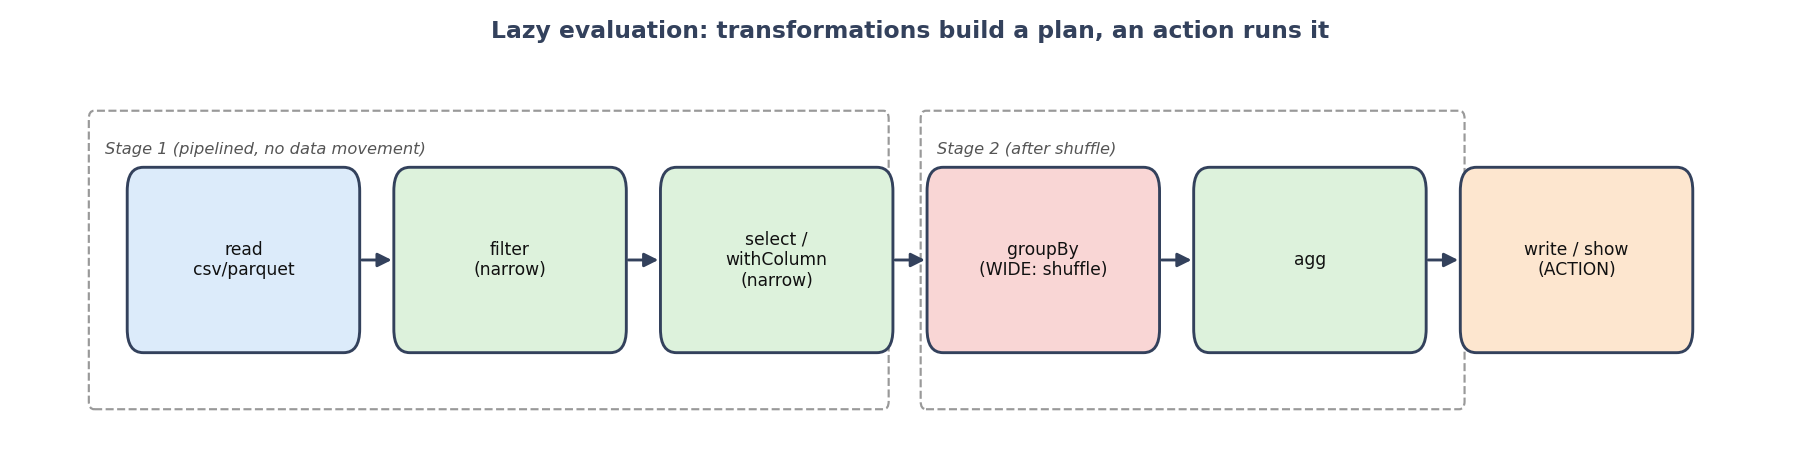

*The shuffle at groupBy splits the job into two stages.*

In [ ]:
big = spark.range(0, 2_000_000).withColumn("key", (F.col("id") % 1000).cast("int")).withColumn("v", F.rand(7))

agg = big.filter("v > 0.1").groupBy("key").agg(F.sum("v").alias("s"))
agg.explain("formatted")      # find 'Exchange hashpartitioning' = the shuffle

## 3.2 Adaptive Query Execution (AQE)
AQE re-optimises at runtime: coalesces tiny shuffle partitions, switches join strategy, and splits skewed partitions. It is on by default in Spark 3.2+; know the knobs.

In [ ]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.adaptive.coalescePartitions.enabled", "true")
spark.conf.set("spark.sql.adaptive.skewJoin.enabled", "true")
print({k: spark.conf.get(k) for k in [
    "spark.sql.adaptive.enabled", "spark.sql.adaptive.skewJoin.enabled", "spark.sql.shuffle.partitions"]})

## 3.3 Join strategies and broadcast joins
When one side is small, **broadcast** it to every executor and skip the shuffle of the big side entirely.

In [ ]:
from pyspark.sql.functions import broadcast

dim = spark.range(0, 1000).withColumnRenamed("id", "key").withColumn("label", F.concat(F.lit("k"), F.col("key")))

j = big.join(broadcast(dim), "key")
j.explain()                   # BroadcastHashJoin instead of SortMergeJoin
print(j.count())

## 3.4 Data skew & salting
If one key holds most rows, one task does most of the work while the others wait. **Salting** spreads the hot key across several partitions.

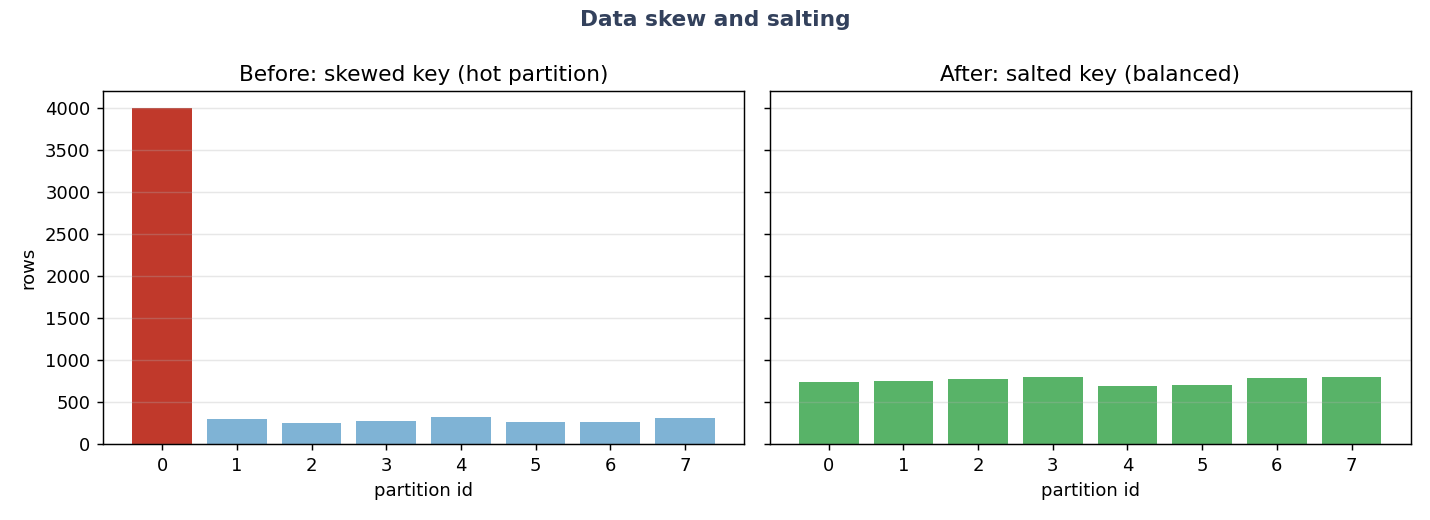

In [ ]:
skewed = (spark.range(0, 400_000)
          .withColumn("key", F.when(F.col("id") % 10 < 8, F.lit("HOT")).otherwise(F.concat(F.lit("k"), F.col("id") % 50)))
          .withColumn("v", F.lit(1)))

SALT = 8
# Stage 1: partial aggregate on (key, salt)   Stage 2: final aggregate on key
salted = (skewed.withColumn("salt", (F.rand(1) * SALT).cast("int"))
                .groupBy("key", "salt").agg(F.sum("v").alias("partial"))
                .groupBy("key").agg(F.sum("partial").alias("total")))
salted.orderBy(F.desc("total")).show(5)

## 3.5 Caching & persistence
Cache a DataFrame only if you **reuse** it several times. Always `unpersist()` when done.

In [ ]:
from pyspark import StorageLevel
import time

expensive = big.groupBy("key").agg(F.sum("v").alias("s"), F.count("*").alias("c"))
expensive.persist(StorageLevel.MEMORY_AND_DISK)
expensive.count()                         # materialise the cache

t = time.time(); expensive.filter("s > 500").count(); print("cached run:", round(time.time() - t, 3), "s")
expensive.unpersist()

## 3.6 Explicit schemas (production habit)
`inferSchema` costs an extra pass and can guess wrong. Declare schemas for reliable pipelines.

In [ ]:
schema = T.StructType([
    T.StructField("customer_id", T.StringType(), False),
    T.StructField("name",        T.StringType(), True),
    T.StructField("city",        T.StringType(), True),
    T.StructField("updated_at",  T.DateType(),   True),
])
print(schema.simpleString())

## 3.7 Medallion pipeline (Bronze → Silver → Gold)
A standard layout for automated pipelines. Airflow (notebook 3) schedules these jobs; dbt (notebook 2) can build the Gold layer.

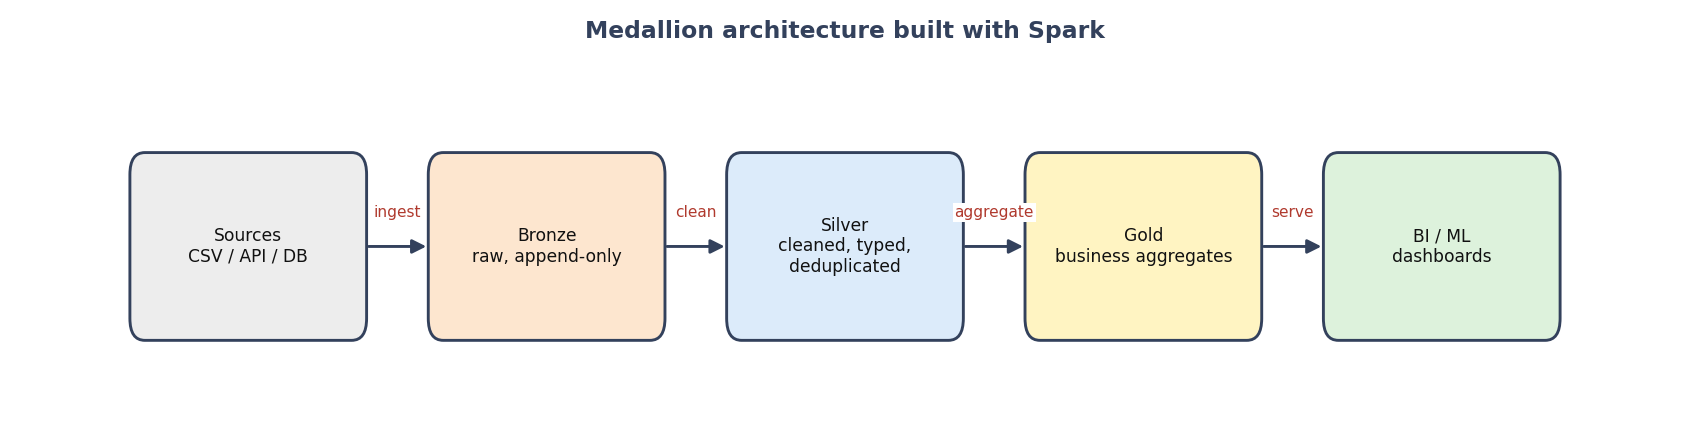

In [ ]:
import shutil
for p in ["lake/bronze", "lake/silver", "lake/gold"]:
    shutil.rmtree(p, ignore_errors=True)

# Bronze: raw, append-only, keep ingestion metadata
bronze = orders.withColumn("_ingested_at", F.current_timestamp()).withColumn("_source", F.lit("orders_api"))
bronze.write.mode("overwrite").parquet("lake/bronze/orders")

# Silver: typed, deduplicated, validated
silver = (spark.read.parquet("lake/bronze/orders")
          .withColumn("order_date", F.to_date("order_date"))
          .dropDuplicates(["order_id"])
          .filter("qty > 0 AND unit_price > 0")
          .withColumn("revenue", F.col("qty") * F.col("unit_price")))
silver.write.mode("overwrite").parquet("lake/silver/orders")

# Gold: business-ready aggregate
gold = (spark.read.parquet("lake/silver/orders")
        .groupBy(F.date_format("order_date", "yyyy-MM").alias("month"), "product")
        .agg(F.sum("revenue").alias("revenue")))
gold.write.mode("overwrite").parquet("lake/gold/monthly_product_revenue")
gold.orderBy("month", "product").show()

## 3.8 SCD Type 2 with Spark
Keep full history of changing attributes: close the old row (`valid_to`, `is_current = false`) and insert a new current row. (dbt does the same with *snapshots*, see notebook 2.)

In [ ]:
dim_cur = spark.createDataFrame(
    [("C1", "Boston", "2025-01-01", None, True), ("C2", "Austin", "2025-01-01", None, True)],
    "customer_id string, city string, valid_from string, valid_to string, is_current boolean"   # explicit schema: valid_to is all-NULL, Spark cannot infer it
).withColumn("valid_from", F.to_date("valid_from")).withColumn("valid_to", F.to_date("valid_to"))

incoming = spark.createDataFrame([("C1", "Denver"), ("C2", "Austin"), ("C3", "Miami")], ["customer_id", "city"])
today = F.to_date(F.lit("2026-03-01"))

cur = dim_cur.filter("is_current")
changed = (incoming.alias("n").join(cur.alias("c"), "customer_id", "left")
           .filter("c.customer_id IS NULL OR n.city <> c.city")
           .select("customer_id", F.col("n.city").alias("city")))

changed_keys = changed.select("customer_id")

# 1) close the current version of every changed key
closed = (cur.join(changed_keys, "customer_id", "left_semi")
          .withColumn("valid_to", today).withColumn("is_current", F.lit(False)))
# 2) rows that stay as they are: old history + current rows that did not change
unchanged_current = cur.join(changed_keys, "customer_id", "left_anti")
history = dim_cur.filter("NOT is_current")
# 3) brand-new current versions (new customers and changed customers)
new_rows = (changed.withColumn("valid_from", today).withColumn("valid_to", F.lit(None).cast("date"))
            .withColumn("is_current", F.lit(True)))

result = history.unionByName(unchanged_current).unionByName(closed).unionByName(new_rows)
result.orderBy("customer_id", "valid_from").show()

## 3.9 Structured Streaming (taste)
Same DataFrame API on unbounded data. The built-in `rate` source needs no external system.

In [ ]:
import time
stream = (spark.readStream.format("rate").option("rowsPerSecond", 20).load()
          .withWatermark("timestamp", "5 seconds")
          .groupBy(F.window("timestamp", "5 seconds")).count())

q = (stream.writeStream.outputMode("update").format("memory").queryName("rate_counts").start())
time.sleep(12)
spark.sql("SELECT window.start, count FROM rate_counts ORDER BY window.start").show(truncate=False)
q.stop()

## 3.10 Testing your transformations
Keep transformations as **pure functions** (DataFrame in → DataFrame out) so you can unit-test them with pytest on tiny local data.

In [ ]:
def add_revenue(df):
    return df.withColumn("revenue", F.col("qty") * F.col("unit_price"))

def test_add_revenue():
    t = spark.createDataFrame([(2, 5.0)], ["qty", "unit_price"])
    assert add_revenue(t).first()["revenue"] == 10.0

test_add_revenue()
print("test passed ✅")

## 3.11 Performance checklist
- Prefer built-in functions; avoid row-wise Python UDFs.
- Filter and select **early**; use columnar formats (Parquet/Delta).
- Avoid unnecessary shuffles; broadcast small dimension tables.
- Watch partition sizes (~128 MB each is a good target) and fix skew.
- Cache only what you reuse; always unpersist.
- Use the **Spark UI** (http://localhost:4040 while a job runs) to inspect stages, shuffle size and skew.

### 🏁 Where next?
Notebook 2 shows how **dbt** transforms the Gold layer in SQL, and notebook 3 shows how **Airflow** schedules Spark + dbt together.

In [ ]:
spark.stop()